In [26]:
#importing modules
import numpy as np
import qiskit.circuit as QuantumCircuit

THIS IS THE QISKIT TUTORIAL, experimenting with the canonical QAE. 
In this notebook, I compared between classical MC and Canonical QAE, to compare the qubit count, shots, and the RMSE through asking it to approximate different p-values.
I discovered the following:
- For certain probability there are qubit counts that doesnt favour the calculation due to it awkardly fitting into the gap between 2 bins, massively increasing the RMSE
- Trivially speaking, the higher qubit count and higher shot, the more accurate it gets -> this leads to the question can we determine the optimal qubit count and number of shots without overkilling it. - IQAE ?????? maybe from the looks of it

Playing around


In [ ]:
import numpy as np
from qiskit.circuit import QuantumCircuit

p = 0.2

class BernoulliA(QuantumCircuit):
    """A circuit representing the Bernoulli A operator."""

    def __init__(self, probability):
        super().__init__(1)  # circuit on 1 qubit

        theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(theta_p, 0)


class BernoulliQ(QuantumCircuit):
    """A circuit representing the Bernoulli Q operator."""

    def __init__(self, probability):
        super().__init__(1)  # circuit on 1 qubit

        self._theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(2 * self._theta_p, 0)

    def power(self, k):
        # implement the efficient power of Q
        q_k = QuantumCircuit(1)
        q_k.ry(2 * k * self._theta_p, 0)
        return q_k

In [29]:
A = BernoulliA(p)
Q = BernoulliQ(p)

In [30]:
from qiskit_algorithms import EstimationProblem

problem = EstimationProblem(
    state_preparation=A,  # A operator
    grover_operator=Q,  # Q operator
    objective_qubits=[0],  # the "good" state Psi1 is identified as measuring |1> in qubit 0
)

In [31]:
from qiskit.primitives import Sampler

sampler = Sampler()

C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_27128\2087805081.py:3: DeprecationWarning: The class ``qiskit.primitives.sampler.Sampler`` is deprecated as of qiskit 1.2. It will be removed no earlier than 3 months after the release date. All implementations of the `BaseSamplerV1` interface have been deprecated in favor of their V2 counterparts. The V2 alternative for the `Sampler` class is `StatevectorSampler`.
  sampler = Sampler()


In [35]:
from qiskit_algorithms import AmplitudeEstimation

ae = AmplitudeEstimation(
    num_eval_qubits=4,  # the number of evaluation qubits specifies circuit width and accuracy
    sampler=sampler,
)
ae_result = ae.estimate(problem)

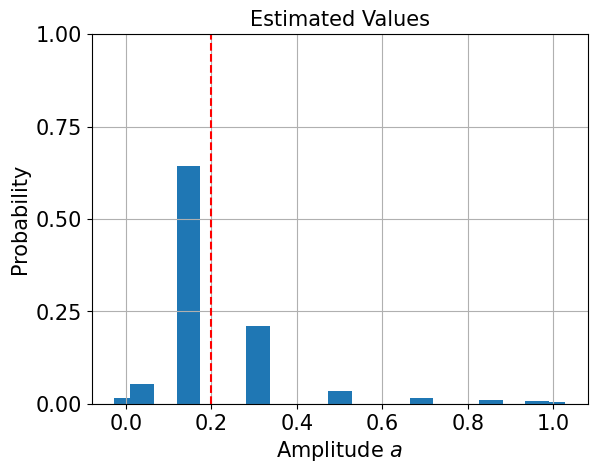

In [36]:
import matplotlib.pyplot as plt

# plot estimated values
gridpoints = list(ae_result.samples.keys())
probabilities = list(ae_result.samples.values())

plt.bar(gridpoints, probabilities, width=0.5 / len(probabilities))
plt.axvline(p, color="r", ls="--")
plt.xticks(size=15)
plt.yticks([0, 0.25, 0.5, 0.75, 1], size=15)
plt.title("Estimated Values", size=15)
plt.ylabel("Probability", size=15)
plt.xlabel(r"Amplitude $a$", size=15)
plt.ylim((0, 1))
plt.grid()
plt.show()

In [37]:
print("Interpolated MLE estimator:", ae_result.mle)

Interpolated MLE estimator: 0.19999999592000506


shots=   100  QAE RMSE=0.001218  Classical RMSE=0.039030
shots=   200  QAE RMSE=0.000793  Classical RMSE=0.030000
shots=   500  QAE RMSE=0.000446  Classical RMSE=0.021445
shots=  1000  QAE RMSE=0.000399  Classical RMSE=0.013142
shots=  2000  QAE RMSE=0.000239  Classical RMSE=0.011524
shots=  5000  QAE RMSE=0.000123  Classical RMSE=0.005533
shots= 10000  QAE RMSE=0.000100  Classical RMSE=0.003652
shots= 20000  QAE RMSE=0.000085  Classical RMSE=0.002965
shots= 50000  QAE RMSE=0.000044  Classical RMSE=0.001722
shots=100000  QAE RMSE=0.000034  Classical RMSE=0.001159


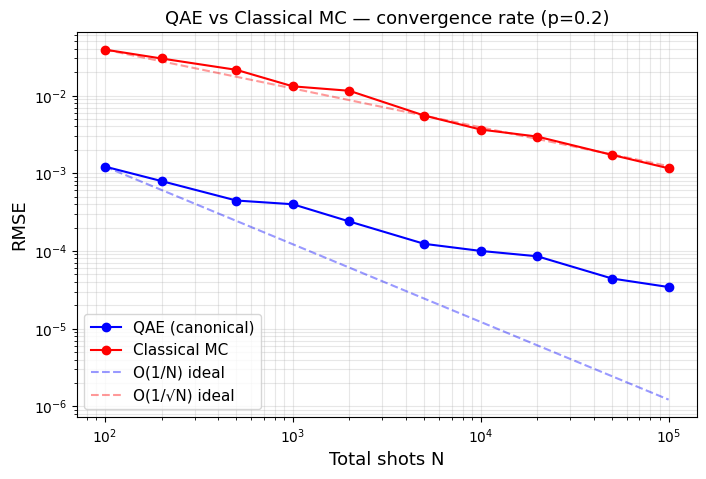


Fitted QAE slope:       -0.516  (ideal = -1.0)
Fitted Classical slope: -0.521  (ideal = -0.5)


In [56]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit_algorithms import AmplitudeEstimation
from qiskit_aer.primitives import Sampler

true_value = 0.2
n_reps = 30
shot_list = [100, 200, 500, 1000, 2000, 5000, 10000, 20000, 50000, 100000]

qae_rmse = []
classical_rmse = []

for shots in shot_list:
    qae_errors = []
    classical_errors = []
    
    for _ in range(n_reps):
        # QAE
        sampler = Sampler(run_options={"shots": shots})
        ae = AmplitudeEstimation(num_eval_qubits=6, sampler=sampler)
        result = ae.estimate(problem)
        qae_errors.append((result.mle - true_value)**2)
        
        # classical MC — flip a biased coin `shots` times
        samples = np.random.binomial(1, true_value, shots)
        classical_errors.append((np.mean(samples) - true_value)**2)
    
    qae_rmse.append(np.sqrt(np.mean(qae_errors)))
    classical_rmse.append(np.sqrt(np.mean(classical_errors)))
    print(f"shots={shots:6d}  QAE RMSE={qae_rmse[-1]:.6f}  Classical RMSE={classical_rmse[-1]:.6f}")

# --- log-log convergence plot ---
N = np.array(shot_list, dtype=float)

plt.figure(figsize=(8, 5))
plt.loglog(shot_list, qae_rmse,       'b-o', label='QAE (canonical)')
plt.loglog(shot_list, classical_rmse, 'r-o', label='Classical MC')

# reference lines anchored at first data point
plt.loglog(N, qae_rmse[0]       * (N[0]/N)**1.0, 'b--', alpha=0.4, label='O(1/N) ideal')
plt.loglog(N, classical_rmse[0] * (N[0]/N)**0.5, 'r--', alpha=0.4, label='O(1/√N) ideal')

plt.xlabel('Total shots N', size=13)
plt.ylabel('RMSE', size=13)
plt.title('QAE vs Classical MC — convergence rate (p=0.2)', size=13)
plt.legend(fontsize=11)
plt.grid(True, which='both', alpha=0.3)
plt.show()

# --- fitted slopes ---
qae_slope       = np.polyfit(np.log(shot_list), np.log(qae_rmse), 1)[0]
classical_slope = np.polyfit(np.log(shot_list), np.log(classical_rmse), 1)[0]
print(f"\nFitted QAE slope:       {qae_slope:.3f}  (ideal = -1.0)")
print(f"Fitted Classical slope: {classical_slope:.3f}  (ideal = -0.5)")

Extension - Tutorial completed above

In [ ]:
import numpy as np
from qiskit_algorithms import AmplitudeEstimation
from qiskit_aer.primitives import Sampler
from qiskit.circuit import QuantumCircuit
from qiskit_algorithms import EstimationProblem
import warnings
warnings.filterwarnings('ignore')

n_reps     = 20
shot_list  = [100, 200, 500, 1000, 2000, 5000, 10000, 20000, 50000, 100000]
qubit_list = [2, 3, 4, 5, 6, 7, 8]
p_values   = [0.05, 0.1, 0.25, 0.5]

all_qae_grids       = {}
all_classical_grids = {}

for p_true in p_values:
    print(f"\n{'='*55}")
    k_max = max(0, int((np.pi / (2*np.arcsin(np.sqrt(p_true))) - 1) / 2))
    print(f"  p={p_true}  |  k_max={k_max}  |  θ={np.arcsin(np.sqrt(p_true)):.3f} rad")
    print(f"{'='*55}")

    qc = QuantumCircuit(1)
    qc.ry(2 * np.arcsin(np.sqrt(p_true)), 0)
    problem = EstimationProblem(state_preparation=qc, objective_qubits=[0])

    # ── classical MC: compute once, reuse across all qubit counts ──
    print("  Computing classical MC...")
    cls_grid = np.zeros((len(qubit_list), len(shot_list)))
    for j, shots in enumerate(shot_list):
        cls_errors = []
        for _ in range(n_reps):
            samples = np.random.binomial(1, p_true, shots)
            cls_errors.append((np.mean(samples) - p_true) ** 2)
        cls_rmse = np.sqrt(np.mean(cls_errors))
        cls_grid[:, j] = cls_rmse        # broadcast same value to all qubit rows
        print(f"    shots={shots:6d} → Classical RMSE={cls_rmse:.5f}")

    # ── QAE: sweep qubit count ──
    qae_grid = np.zeros((len(qubit_list), len(shot_list)))
    for i, n_qubits in enumerate(qubit_list):
        for j, shots in enumerate(shot_list):
            qae_errors = []
            for _ in range(n_reps):
                sampler = Sampler(run_options={"shots": shots})
                ae      = AmplitudeEstimation(
                            num_eval_qubits=n_qubits,
                            sampler=sampler)
                result  = ae.estimate(problem)
                qae_errors.append((result.mle - p_true) ** 2)
            qae_grid[i, j] = np.sqrt(np.mean(qae_errors))
            print(f"  n={n_qubits}, shots={shots:6d} → "
                  f"QAE={qae_grid[i,j]:.5f}  "
                  f"Classical={cls_grid[i,j]:.5f}")

    all_qae_grids[p_true]       = qae_grid
    all_classical_grids[p_true] = cls_grid

print("\nDone. Run plot cell.")


  p=0.05  |  k_max=2  |  θ=0.226 rad
  Computing classical MC...
    shots=   100 → Classical RMSE=0.01844
    shots=   200 → Classical RMSE=0.01479
    shots=   500 → Classical RMSE=0.00972
    shots=  1000 → Classical RMSE=0.00835
    shots=  2000 → Classical RMSE=0.00433
    shots=  5000 → Classical RMSE=0.00310
    shots= 10000 → Classical RMSE=0.00187
    shots= 20000 → Classical RMSE=0.00184
    shots= 50000 → Classical RMSE=0.00084
    shots=100000 → Classical RMSE=0.00075
  n=2, shots=   100 → QAE=0.01178  Classical=0.01844
  n=2, shots=   200 → QAE=0.00762  Classical=0.01479
  n=2, shots=   500 → QAE=0.00490  Classical=0.00972
  n=2, shots=  1000 → QAE=0.00433  Classical=0.00835
  n=2, shots=  2000 → QAE=0.00224  Classical=0.00433
  n=2, shots=  5000 → QAE=0.00161  Classical=0.00310
  n=2, shots= 10000 → QAE=0.00109  Classical=0.00187
  n=2, shots= 20000 → QAE=0.00067  Classical=0.00184
  n=2, shots= 50000 → QAE=0.00043  Classical=0.00084
  n=2, shots=100000 → QAE=0.00028  Cl

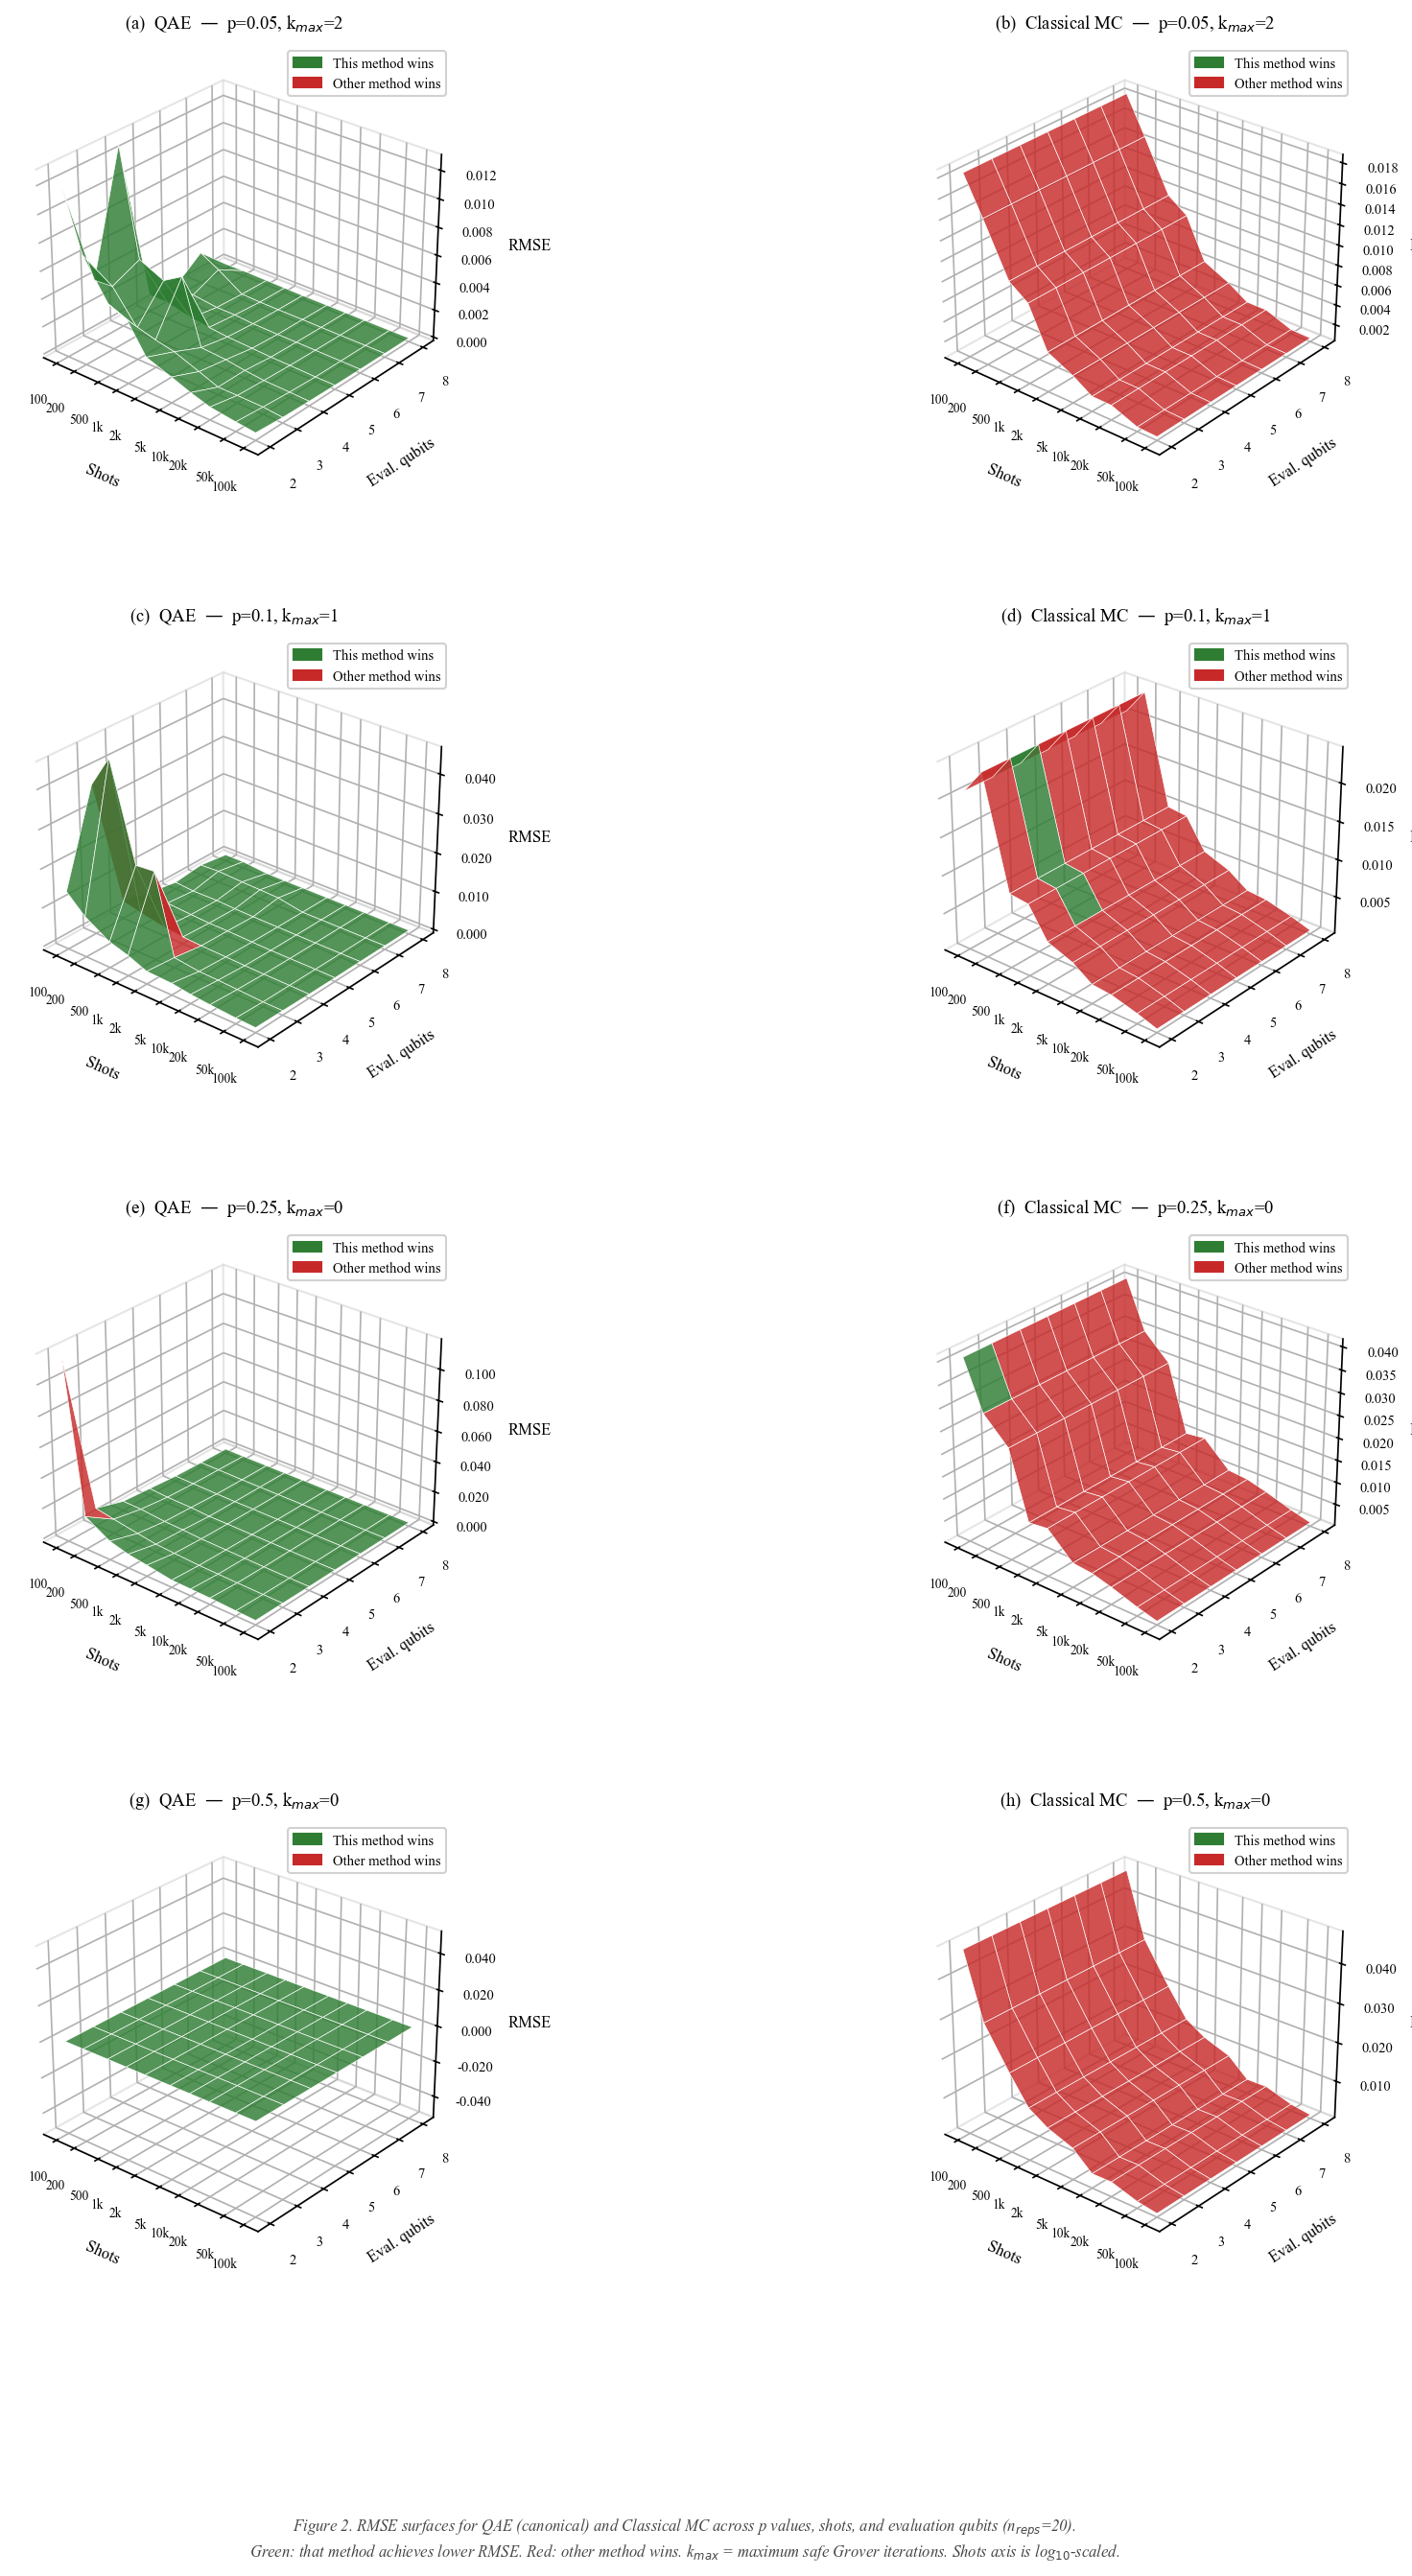

saved → qae_vs_classical_p_sweep.pdf / .png


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import rcParams
import matplotlib.ticker as ticker

rcParams.update({
    'font.family':    'serif',
    'font.serif':     ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'font.size':      10,
    'axes.titlesize': 10,
    'axes.labelsize': 9,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'figure.dpi':     150,
})

X, Y         = np.meshgrid(shot_list, qubit_list)
logX         = np.log10(X)
xtick_pos    = np.log10(shot_list)
xtick_labels = ['100','200','500','1k','2k','5k','10k','20k','50k','100k']

def build_facecolors(qae_grid, cls_grid, invert=False):
    rows, cols = qae_grid.shape
    fc = np.empty((rows - 1, cols - 1, 4))
    for i in range(rows - 1):
        for j in range(cols - 1):
            qae_wins = qae_grid[i, j] < cls_grid[i, j]
            if not invert:
                rgba = (0.18, 0.49, 0.20, 0.82) if qae_wins \
                       else (0.78, 0.16, 0.16, 0.82)
            else:
                rgba = (0.18, 0.49, 0.20, 0.82) if not qae_wins \
                       else (0.78, 0.16, 0.16, 0.82)
            fc[i, j] = rgba
    return fc

def style_ax(ax, title):
    ax.set_xlabel('Shots',        labelpad=6, fontsize=8)
    ax.set_ylabel('Eval. qubits', labelpad=6, fontsize=8)
    ax.set_zlabel('RMSE',         labelpad=6, fontsize=8)
    ax.set_title(title, pad=8, fontweight='normal', fontsize=9)
    ax.set_xticks(xtick_pos)
    ax.set_xticklabels(xtick_labels, fontsize=6.5)
    ax.set_yticks(qubit_list)
    ax.zaxis.set_major_formatter(ticker.FormatStrFormatter('%.3f'))
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.pane.set_edgecolor('#cccccc')
    ax.yaxis.pane.set_edgecolor('#cccccc')
    ax.zaxis.pane.set_edgecolor('#cccccc')
    ax.grid(True, linestyle='--', linewidth=0.35, alpha=0.5)
    ax.view_init(elev=28, azim=-50)

h_win  = mpatches.Patch(color=(0.18,0.49,0.20), label='This method wins')
h_lose = mpatches.Patch(color=(0.78,0.16,0.16), label='Other method wins')

# one row per p value, two columns (QAE | Classical)
n_rows = len(p_values)
fig    = plt.figure(figsize=(13, 5 * n_rows))
fig.patch.set_facecolor('white')

for row, p_true in enumerate(p_values):
    qae_grid = all_qae_grids[p_true]
    cls_grid = all_classical_grids[p_true]
    fc_qae   = np.pad(build_facecolors(qae_grid, cls_grid, invert=False),
                      ((0,1),(0,1),(0,0)), mode='edge')
    fc_cls   = np.pad(build_facecolors(qae_grid, cls_grid, invert=True),
                      ((0,1),(0,1),(0,0)), mode='edge')

    k_max = max(0, int((np.pi / (2*np.arcsin(np.sqrt(p_true))) - 1) / 2))

    # QAE panel
    ax1 = fig.add_subplot(n_rows, 2, row*2 + 1, projection='3d')
    ax1.plot_surface(logX, Y, qae_grid,
                     facecolors=fc_qae, edgecolor='white',
                     linewidth=0.3, shade=False)
    style_ax(ax1, f'({"abcdefgh"[row*2]})  QAE  —  p={p_true}, '
                  f'k$_{{max}}$={k_max}')
    ax1.legend(handles=[h_win, h_lose], loc='upper right',
               fontsize=7, framealpha=0.9, edgecolor='#cccccc')

    # Classical panel
    ax2 = fig.add_subplot(n_rows, 2, row*2 + 2, projection='3d')
    ax2.plot_surface(logX, Y, cls_grid,
                     facecolors=fc_cls, edgecolor='white',
                     linewidth=0.3, shade=False)
    style_ax(ax2, f'({"abcdefgh"[row*2+1]})  Classical MC  —  p={p_true}, '
                  f'k$_{{max}}$={k_max}')
    ax2.legend(handles=[h_win, h_lose], loc='upper right',
               fontsize=7, framealpha=0.9, edgecolor='#cccccc')

fig.text(
    0.5, 0.005,
    'Figure 2. RMSE surfaces for QAE (canonical) and Classical MC across '
    'p values, shots, and evaluation qubits (n$_{reps}$=20).\n'
    'Green: that method achieves lower RMSE. Red: other method wins. '
    'k$_{max}$ = maximum safe Grover iterations. Shots axis is log$_{10}$-scaled.',
    ha='center', va='bottom', fontsize=8, style='italic', color='#444444'
)

plt.subplots_adjust(left=0.04, right=0.96, hspace=0.35, wspace=0.1)
plt.savefig('qae_vs_classical_p_sweep.pdf', dpi=300,
            bbox_inches='tight', facecolor='white')
plt.show()
print("saved → qae_vs_classical_p_sweep.pdf / .png")

Canonical QAE if fundamentally discrete

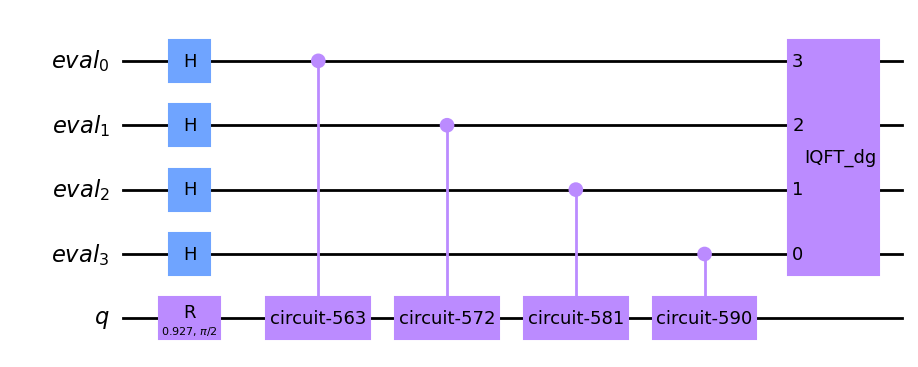

In [ ]:
#Graphing the circuit
ae_circuit = ae.construct_circuit(problem)
ae_circuit.decompose().draw(
    "mpl", style="clifford"
)  # decompose 1 level: exposes the Phase estimation circuit!